# Notebook 02 — Mathematical Foundations of Neural Networks

**Learning path:** Deep Learning with TensorFlow  
**Level:** Beginner to Intermediate  
**Part:** Part I — Foundations of Deep Learning  
**Notebook version:** 1.0

---

## Chapter Overview

Neural networks are built from a small set of mathematical operations: tensor operations, matrix multiplication, affine transformations, nonlinear functions, derivatives, and gradient-based optimization. This notebook develops those ideas step by step and connects each mathematical object to the computations performed by a neural network.

The emphasis is practical. We will use **NumPy** to calculate examples, visualize geometric transformations, estimate derivatives, implement gradient descent, and train a small neural network from scratch. The goal is to understand the mathematics before relying on automatic differentiation frameworks.

> **Scope note:** This notebook focuses on the mathematical foundations needed for feedforward neural networks. Probability, information theory, convolution, and more advanced optimization methods will be developed in later chapters.

## Notebook Roadmap

| Section | Topic |
|---|---|
| 1 | Learning objectives, notation, and computational setup |
| 2 | Scalars, vectors, matrices, and tensors |
| 3 | Vector operations, dot products, and norms |
| 4 | Matrix multiplication and dimensions |
| 5 | Linear transformations and affine layers |
| 6 | Derivatives and numerical differentiation |
| 7 | Partial derivatives and gradients |
| 8 | The chain rule and computational graphs |
| 9 | Loss functions and gradient descent |
| 10 | Gradient checking and a neural network from scratch |
| 11 | Common mathematical and implementation mistakes |
| 12 | Summary, glossary, and exercises |

### Learning Objectives

After completing this notebook, you should be able to:

- Distinguish scalars, vectors, matrices, and higher-dimensional tensors, and describe their shapes.
- Calculate vector dot products, norms, transposes, and matrix products.
- Explain how a dense neural-network layer is expressed as a matrix operation.
- Distinguish a linear transformation from an affine transformation.
- Interpret derivatives, partial derivatives, and gradients geometrically.
- Apply the chain rule to a sequence of mathematical operations.
- Explain the gradient-descent update and the effect of the learning rate.
- Compare analytical gradients with finite-difference numerical estimates.
- Implement forward propagation and backpropagation for a small multilayer perceptron using NumPy.

### Prerequisites

- Basic Python syntax and functions.
- The idea of an artificial neuron, weights, biases, and activation functions from Notebook 01.
- Basic familiarity with NumPy arrays is helpful, but the required operations are introduced here.

### Conventions Used in This Notebook

- A scalar is written as a lowercase symbol, for example $x$.
- A vector is written as a lowercase bold symbol, for example $\mathbf{x}$.
- A matrix is written as an uppercase bold symbol, for example $\mathbf{W}$.
- $n$ denotes the number of samples, $d$ the number of input features, and $h$ the number of hidden units.
- In batched neural-network calculations, **rows represent samples** and **columns represent features or units**.
- Unless stated otherwise, vectors are represented by one-dimensional NumPy arrays with shape `(dimension,)`. For matrix-based batch calculations, we explicitly use two-dimensional arrays.

---
# 1. Mathematical Objects and Tensor Notation

## 1.1 Why Mathematics Matters in Deep Learning

A neural network repeatedly transforms numerical data. Each layer receives an array, multiplies it by learnable parameters, adds a bias, and usually applies a nonlinear activation function.

A simplified dense layer can be written as:

$$
\mathbf{a} = \phi(\mathbf{x}\mathbf{W} + \mathbf{b})
$$

Here, $\mathbf{x}$ contains input features, $\mathbf{W}$ contains weights, $\mathbf{b}$ contains biases, and $\phi$ is an activation function. Understanding the shapes and operations in this expression helps prevent many implementation errors.

## 1.2 Scalars

A **scalar** is a single numerical value. Examples include a learning rate, a loss value, or one model parameter.

$$
x = 3.5
$$

In NumPy, a scalar can be represented by a Python number or a zero-dimensional NumPy array. A zero-dimensional array has shape `()`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A Python scalar and a zero-dimensional NumPy array.
python_scalar = 3.5
numpy_scalar = np.array(3.5)

print("Python scalar:", python_scalar)
print("NumPy scalar value:", numpy_scalar)
print("NumPy scalar shape:", numpy_scalar.shape)
print("Number of dimensions:", numpy_scalar.ndim)

Python scalar: 3.5
NumPy scalar value: 3.5
NumPy scalar shape: ()
Number of dimensions: 0


## 1.3 Vectors

A **vector** is an ordered collection of numbers. In a machine-learning dataset, one vector often represents the features of one sample.

$$
\mathbf{x} = \begin{bmatrix}x_1 & x_2 & \cdots & x_d\end{bmatrix}
$$

A one-dimensional NumPy array with $d$ elements has shape `(d,)`. It is important not to confuse the shape `(d,)` with `(d, 1)`: the first is a one-dimensional array, while the second is a two-dimensional column matrix.

In [2]:
# A one-dimensional vector containing three features.
x = np.array([1.2, 0.7, -0.4], dtype=float)

print("Vector:", x)
print("Shape:", x.shape)
print("Number of dimensions:", x.ndim)

# Reshape the vector into a column matrix.
x_column = x.reshape(3, 1)
print("\nColumn representation:\n", x_column)
print("Column shape:", x_column.shape)

Vector: [ 1.2  0.7 -0.4]
Shape: (3,)
Number of dimensions: 1

Column representation:
 [[ 1.2]
 [ 0.7]
 [-0.4]]
Column shape: (3, 1)


## 1.4 Matrices

A **matrix** is a rectangular arrangement of numbers with rows and columns. A data matrix commonly stores multiple samples:

$$
\mathbf{X} =
\begin{bmatrix}
 x_{11} & x_{12} & \cdots & x_{1d} \\
 x_{21} & x_{22} & \cdots & x_{2d} \\
 \vdots & \vdots & \ddots & \vdots \\
 x_{n1} & x_{n2} & \cdots & x_{nd}
\end{bmatrix}
\in \mathbb{R}^{n\times d}
$$

The shape $(n,d)$ means that the matrix contains $n$ samples and $d$ features per sample.

In [3]:
# Four samples, each described by three features.
X = np.array(
    [
        [1.0, 0.2, 0.5],
        [0.3, 0.8, 0.1],
        [0.9, 0.4, 0.7],
        [0.2, 0.6, 0.3],
    ],
    dtype=float,
)

print("Data matrix:\n", X)
print("Shape (samples, features):", X.shape)
print("Number of dimensions:", X.ndim)

Data matrix:
 [[1.  0.2 0.5]
 [0.3 0.8 0.1]
 [0.9 0.4 0.7]
 [0.2 0.6 0.3]]
Shape (samples, features): (4, 3)
Number of dimensions: 2


## 1.5 Higher-Dimensional Tensors

A **tensor** is a general term for a numerical object with zero or more dimensions. In this terminology:

| Object | Number of dimensions (rank) | Example shape |
|---|---:|---|
| Scalar | 0 | `()` |
| Vector | 1 | `(5,)` |
| Matrix | 2 | `(4, 5)` |
| 3-D tensor | 3 | `(8, 32, 32)` |
| 4-D tensor | 4 | `(16, 32, 32, 3)` |

For example, a batch of RGB images can be represented by a four-dimensional array with shape `(batch_size, height, width, channels)`. The word *rank* here refers to the number of dimensions, not matrix rank from linear algebra.

In [4]:
# Example: a batch of 10 small RGB images, each 32 x 32 pixels.
image_batch = np.zeros((10, 32, 32, 3), dtype=np.float32)

print("Image batch shape:", image_batch.shape)
print("Tensor rank / number of dimensions:", image_batch.ndim)
print("Number of elements:", image_batch.size)

Image batch shape: (10, 32, 32, 3)
Tensor rank / number of dimensions: 4
Number of elements: 30720


### Shape-Reading Exercise

Read the shape `(64, 20)` as 64 samples, each with 20 features. Read `(64, 20, 5)` as 64 samples, each represented by a 20-by-5 structure. The meaning of each axis depends on the application, so always document the axis order.

---
# 2. Vector Operations, Dot Products, and Norms

## 2.1 Element-Wise Operations

Element-wise operations act on corresponding entries. If two vectors have the same shape, their element-wise sum and product are:

$$
\mathbf{a}+\mathbf{b} = [a_1+b_1,\ldots,a_d+b_d]
$$

$$
\mathbf{a}\odot\mathbf{b} = [a_1b_1,\ldots,a_db_d]
$$

The symbol $\odot$ is often used to distinguish element-wise multiplication from matrix multiplication.

In [5]:
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 5.0, 6.0])

print("Element-wise addition:", a + b)
print("Element-wise multiplication:", a * b)
print("Scalar multiplication:", 2.0 * a)

Element-wise addition: [5. 7. 9.]
Element-wise multiplication: [ 4. 10. 18.]
Scalar multiplication: [2. 4. 6.]


## 2.2 The Dot Product

The **dot product** combines two vectors of equal length and returns one scalar:

$$
\mathbf{a}\cdot\mathbf{b} = \sum_{i=1}^{d} a_i b_i
$$

For nonzero vectors, the dot product is also related to the angle $\theta$ between them:

$$
\mathbf{a}\cdot\mathbf{b} = \|\mathbf{a}\|_2\|\mathbf{b}\|_2\cos(\theta)
$$

This geometric interpretation is useful: a positive dot product indicates an angle below 90 degrees, a zero dot product indicates orthogonality, and a negative dot product indicates an angle above 90 degrees.

A single artificial neuron uses a dot product to combine its input features and weights:

$$
z = \mathbf{x}\cdot\mathbf{w}+b
$$

In [6]:
x = np.array([0.7, -1.2, 0.5])
w = np.array([0.4, 0.8, -0.3])
bias = 0.2

weighted_sum = np.dot(x, w) + bias
print("Dot product:", np.dot(x, w))
print("Bias:", bias)
print("Neuron pre-activation (z):", weighted_sum)

# The @ operator also performs a dot product for 1-D arrays.
print("Same result using @:", x @ w)

Dot product: -0.83
Bias: 0.2
Neuron pre-activation (z): -0.6299999999999999
Same result using @: -0.83


## 2.3 Vector Norms

A **norm** measures the size or length of a vector. Two common examples are the $L_1$ norm and the Euclidean or $L_2$ norm:

$$
\|\mathbf{x}\|_1 = \sum_{i=1}^{d}|x_i|
$$

$$
\|\mathbf{x}\|_2 = \sqrt{\sum_{i=1}^{d}x_i^2}
$$

The $L_2$ norm is the ordinary geometric length. Norms also appear in regularization, where a penalty can discourage parameters from becoming excessively large. The detailed use of regularization will be covered in Notebook 07.

In [7]:
vector = np.array([3.0, -4.0, 12.0])

l1_norm = np.linalg.norm(vector, ord=1)
l2_norm = np.linalg.norm(vector, ord=2)

print("Vector:", vector)
print("L1 norm:", l1_norm)
print("L2 norm:", l2_norm)

Vector: [ 3. -4. 12.]
L1 norm: 19.0
L2 norm: 13.0


## 2.4 Transpose

The **transpose** swaps the rows and columns of a matrix. If $\mathbf{A}$ has shape $(m,n)$, then $\mathbf{A}^T$ has shape $(n,m)$.

$$
\mathbf{A} =
\begin{bmatrix}1&2&3\\4&5&6\end{bmatrix},
\qquad
\mathbf{A}^T =
\begin{bmatrix}1&4\\2&5\\3&6\end{bmatrix}
$$

Transpose operations are essential in neural-network gradients. For example, multiplying a batch of input data by a weight matrix uses one orientation, while calculating the gradient with respect to those weights usually involves the transpose of the input matrix.

In [8]:
A = np.array([[1, 2, 3], [4, 5, 6]], dtype=float)

print("A shape:", A.shape)
print("A transpose:\n", A.T)
print("Transpose shape:", A.T.shape)

A shape: (2, 3)
A transpose:
 [[1. 4.]
 [2. 5.]
 [3. 6.]]
Transpose shape: (3, 2)


---
# 3. Matrix Multiplication and Neural-Network Dimensions

## 3.1 Matrix Multiplication

Matrix multiplication is different from element-wise multiplication. If $\mathbf{A}$ has shape $(m,k)$ and $\mathbf{B}$ has shape $(k,n)$, their product is defined and has shape $(m,n)$:

$$
\underbrace{\mathbf{A}}_{m\times k}
\underbrace{\mathbf{B}}_{k\times n}
=
\underbrace{\mathbf{C}}_{m\times n}
$$

The inner dimensions must match. Each output entry is the dot product of one row of $\mathbf{A}$ and one column of $\mathbf{B}$:

$$
c_{ij} = \sum_{r=1}^{k} a_{ir}b_{rj}
$$

In [9]:
A = np.array([[1, 2, 3], [4, 5, 6]], dtype=float)  # Shape: (2, 3)
B = np.array([[1, 2], [0, 1], [2, 1]], dtype=float)  # Shape: (3, 2)

C = A @ B
print("A shape:", A.shape)
print("B shape:", B.shape)
print("A @ B:\n", C)
print("Product shape:", C.shape)

A shape: (2, 3)
B shape: (3, 2)
A @ B:
 [[ 7.  7.]
 [16. 19.]]
Product shape: (2, 2)


## 3.2 Element-Wise Multiplication Versus Matrix Multiplication

For arrays with the same shape, `A * B` multiplies corresponding elements. The expression `A @ B` performs matrix multiplication when the dimensions are compatible. These operations answer different mathematical questions and should not be interchanged.

In [10]:
A = np.array([[1, 2], [3, 4]], dtype=float)
B = np.array([[5, 6], [7, 8]], dtype=float)

print("Element-wise product A * B:\n", A * B)
print("Matrix product A @ B:\n", A @ B)

Element-wise product A * B:
 [[ 5. 12.]
 [21. 32.]]
Matrix product A @ B:
 [[19. 22.]
 [43. 50.]]


## 3.3 Deriving the Shape of a Dense Layer

Suppose a batch contains $n$ samples, each with $d$ input features. We want a dense layer with $h$ neurons. Using row-wise samples:

- Input matrix: $\mathbf{X}\in\mathbb{R}^{n\times d}$
- Weight matrix: $\mathbf{W}\in\mathbb{R}^{d\times h}$
- Bias vector: $\mathbf{b}\in\mathbb{R}^{h}$
- Pre-activation matrix: $\mathbf{Z}\in\mathbb{R}^{n\times h}$

The layer is calculated as:

$$
\mathbf{Z}=\mathbf{X}\mathbf{W}+\mathbf{b}
$$

The bias is added to every sample row. NumPy supports this with broadcasting, which will be demonstrated in the next example.

In [11]:
# Five samples, three input features, and four neurons in the layer.
rng = np.random.default_rng(12)
X_batch = rng.normal(size=(5, 3))
W = rng.normal(size=(3, 4))
b = rng.normal(size=(4,))

Z = X_batch @ W + b

print("X_batch:", X_batch.shape)
print("W:", W.shape)
print("b:", b.shape)
print("Z = X_batch @ W + b:", Z.shape)
assert Z.shape == (5, 4)

X_batch: (5, 3)
W: (3, 4)
b: (4,)
Z = X_batch @ W + b: (5, 4)


## 3.4 Broadcasting

**Broadcasting** allows NumPy to perform element-wise operations on arrays with compatible shapes without manually copying the smaller array. For a dense layer, a bias vector with shape `(h,)` can be added to a matrix with shape `(n, h)`: the bias is applied to each of the $n$ rows.

A simplified compatibility rule is to compare dimensions from right to left. Two dimensions are compatible when they are equal or when at least one of them is 1. Missing leading dimensions are treated as 1.

Broadcasting is convenient, but it can also hide shape mistakes. Always inspect the resulting shape and verify that the operation represents the intended mathematics.

In [12]:
matrix = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
bias = np.array([0.1, 0.2, 0.3])

result = matrix + bias
print("Matrix shape:", matrix.shape)
print("Bias shape:", bias.shape)
print("Result:\n", result)
print("Result shape:", result.shape)

Matrix shape: (2, 3)
Bias shape: (3,)
Result:
 [[1.1 2.2 3.3]
 [4.1 5.2 6.3]]
Result shape: (2, 3)


### Shape-Checking Practice

Before multiplying two matrices, write their shapes on paper. For example, $(12,5)@(5,8)$ is valid and produces shape $(12,8)$. In contrast, $(12,5)@(8,5)$ is invalid because the inner dimensions 5 and 8 do not match.

In [13]:
# The following compatibility check reports the expected output shape.
def matmul_output_shape(shape_a, shape_b):
    """Return the 2-D matrix-product shape or raise a helpful error."""
    if len(shape_a) != 2 or len(shape_b) != 2:
        raise ValueError("This helper expects two 2-D matrix shapes.")
    if shape_a[1] != shape_b[0]:
        raise ValueError(
            f"Incompatible shapes: {shape_a} and {shape_b}; "
            "the inner dimensions must match."
        )
    return (shape_a[0], shape_b[1])

print("Valid product:", matmul_output_shape((12, 5), (5, 8)))
try:
    matmul_output_shape((12, 5), (8, 5))
except ValueError as error:
    print("Expected shape error:", error)

Valid product: (12, 8)
Expected shape error: Incompatible shapes: (12, 5) and (8, 5); the inner dimensions must match.


---
# 4. Linear Transformations and Affine Layers

## 4.1 What Is a Linear Transformation?

A transformation $T$ is linear when it preserves vector addition and scalar multiplication:

$$
T(\mathbf{x}+\mathbf{y})=T(\mathbf{x})+T(\mathbf{y})
$$

$$
T(c\mathbf{x})=cT(\mathbf{x})
$$

Matrix multiplication, $T(\mathbf{x})=\mathbf{A}\mathbf{x}$, defines a linear transformation. Geometrically, a two-dimensional linear transformation can rotate, reflect, stretch, compress, or shear points. It always maps the origin to the origin.

## 4.2 Visualizing Common 2-D Transformations

We will apply several matrices to the same collection of points. Each transformation is linear, so the origin remains fixed. The examples are geometric illustrations of matrix multiplication, not neural-network training experiments.

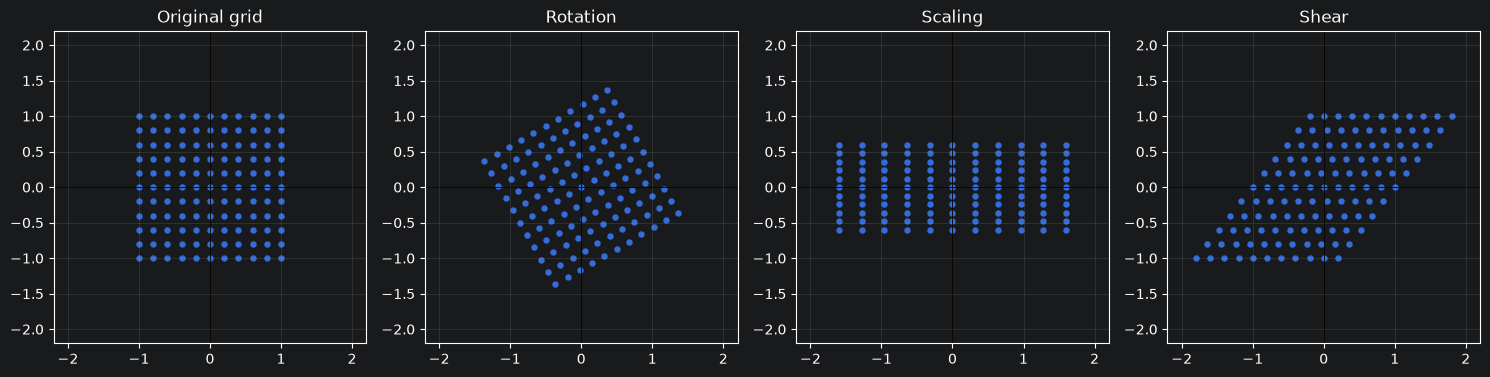

In [14]:
# Create a grid of points in the two-dimensional plane.
coords = np.linspace(-1.0, 1.0, 11)
xx, yy = np.meshgrid(coords, coords)
points = np.vstack([xx.ravel(), yy.ravel()])

angle = np.deg2rad(30)
rotation = np.array(
    [[np.cos(angle), -np.sin(angle)],
     [np.sin(angle),  np.cos(angle)]]
)
scaling = np.array([[1.6, 0.0], [0.0, 0.6]])
shear = np.array([[1.0, 0.8], [0.0, 1.0]])

transforms = [
    ("Original grid", np.eye(2)),
    ("Rotation", rotation),
    ("Scaling", scaling),
    ("Shear", shear),
]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (title, matrix) in zip(axes, transforms):
    transformed = matrix @ points
    ax.scatter(transformed[0], transformed[1], s=13)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4.3 Affine Transformations: Why Neural Layers Have Biases

A dense neural-network layer generally performs an **affine transformation** before applying an activation function:

$$
T(\mathbf{x})=\mathbf{x}\mathbf{W}+\mathbf{b}
$$

The bias translates the output. Therefore, when $\mathbf{b}\ne\mathbf{0}$, the mapping is generally affine rather than linear. In one dimension, $y=2x+1$ is a line that does not pass through the origin, while $y=2x$ is linear.

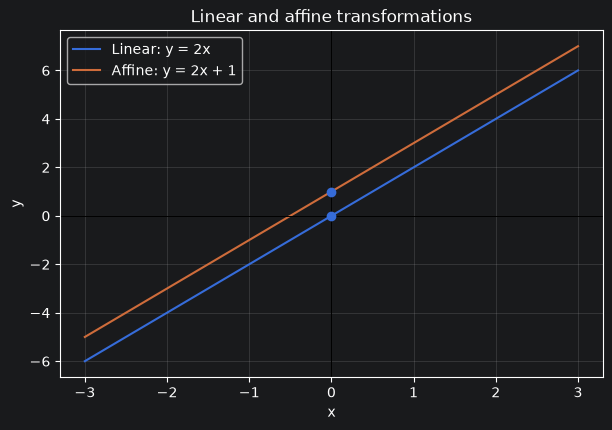

In [15]:
x_values = np.linspace(-3, 3, 200)
linear_values = 2 * x_values
affine_values = 2 * x_values + 1

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x_values, linear_values, label="Linear: y = 2x")
ax.plot(x_values, affine_values, label="Affine: y = 2x + 1")
ax.scatter([0, 0], [0, 1], zorder=3)
ax.axhline(0, color="black", linewidth=0.7)
ax.axvline(0, color="black", linewidth=0.7)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Linear and affine transformations")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 4.4 Why Neural Networks Need Nonlinear Activations

A composition of linear transformations is still a linear transformation. For example:

$$
\mathbf{x}\mathbf{W}_1\mathbf{W}_2
=\mathbf{x}(\mathbf{W}_1\mathbf{W}_2)
$$

Consequently, stacking layers without nonlinear activations does not create the expressive power associated with deep neural networks. Biases make the individual layers affine, but a composition of affine transformations is still affine. Nonlinear activation functions are what allow a multilayer network to represent nonlinear mappings.

In [16]:
# Demonstrate that two affine layers without nonlinear activations
# can be combined into one affine transformation.
rng = np.random.default_rng(21)
X_demo = rng.normal(size=(6, 3))
W1 = rng.normal(size=(3, 4))
b1 = rng.normal(size=(4,))
W2 = rng.normal(size=(4, 2))
b2 = rng.normal(size=(2,))

layer_by_layer = (X_demo @ W1 + b1) @ W2 + b2
combined_weights = W1 @ W2
combined_bias = b1 @ W2 + b2
combined = X_demo @ combined_weights + combined_bias

print("Maximum absolute difference:", np.max(np.abs(layer_by_layer - combined)))
assert np.allclose(layer_by_layer, combined)

Maximum absolute difference: 4.440892098500626e-16


---
# 5. Derivatives and Numerical Differentiation

## 5.1 The Derivative of a Function

The derivative measures the instantaneous rate of change of a function. For a one-variable function $f(x)$, the derivative at $x$ is defined by the limit:

$$
f'(x)=\lim_{h\to 0}\frac{f(x+h)-f(x)}{h}
$$

Geometrically, $f'(x)$ is the slope of the tangent line to the function at that point. A positive derivative means the function is increasing locally; a negative derivative means it is decreasing locally; and a zero derivative indicates a stationary point, although not every stationary point is a minimum.

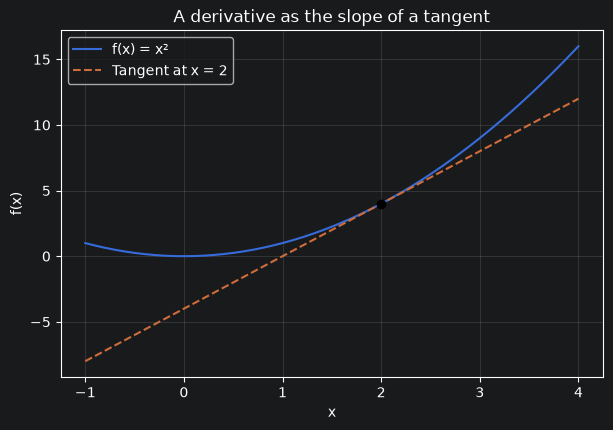

Secant slope with h = 0.5: 4.5
Analytical derivative at x = 2: 4.0


In [17]:
def f(x):
    """A simple differentiable function used for visualization."""
    return x**2

x0 = 2.0
h = 0.5
secant_slope = (f(x0 + h) - f(x0)) / h
analytical_slope = 2 * x0

x_values = np.linspace(-1, 4, 300)
tangent = f(x0) + analytical_slope * (x_values - x0)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x_values, f(x_values), label="f(x) = x²")
ax.plot(x_values, tangent, "--", label="Tangent at x = 2")
ax.scatter([x0], [f(x0)], color="black", zorder=3)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("A derivative as the slope of a tangent")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

print("Secant slope with h = 0.5:", secant_slope)
print("Analytical derivative at x = 2:", analytical_slope)

## 5.2 Common Derivative Rules

Several basic rules are used repeatedly in neural-network calculations:

| Function | Derivative |
|---|---|
| $f(x)=c$ | $f'(x)=0$ |
| $f(x)=x^n$ | $f'(x)=nx^{n-1}$ |
| $f(x)=cf_1(x)$ | $f'(x)=cf_1'(x)$ |
| $f(x)=f_1(x)+f_2(x)$ | $f'(x)=f_1'(x)+f_2'(x)$ |
| $f(x)=e^x$ | $f'(x)=e^x$ |
| $f(x)=\log x$, $x>0$ | $f'(x)=1/x$ |
| $f(x)=\tanh x$ | $f'(x)=1-\tanh^2 x$ |

For the sigmoid function $\sigma(x)=1/(1+e^{-x})$, its derivative can be expressed using the function itself:

$$
\sigma'(x)=\sigma(x)(1-\sigma(x))
$$

These derivatives are important because backpropagation repeatedly applies derivative rules to the operations in a network.

## 5.3 Finite-Difference Approximation

In numerical differentiation, we approximate a derivative using nearby function values. A central-difference approximation is:

$$
f'(x)\approx\frac{f(x+h)-f(x-h)}{2h}
$$

The approximation generally improves as $h$ becomes smaller, but an extremely small step can introduce floating-point round-off error. This trade-off is one reason numerical gradients are useful for checking analytical gradients rather than replacing them in large training jobs.

In [18]:
def central_difference(function, x, step=1e-5):
    """Estimate the derivative of a scalar function at x."""
    if step <= 0:
        raise ValueError("step must be positive")
    return (function(x + step) - function(x - step)) / (2 * step)

function = lambda value: value**3 - 2 * value**2 + value
point = 1.5
analytical = 3 * point**2 - 4 * point + 1

for step in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
    estimate = central_difference(function, point, step)
    print(f"step={step:>8.0e} | estimate={estimate: .8f} | absolute error={abs(estimate - analytical):.2e}")

print("Analytical derivative:", analytical)

step=   1e-01 | estimate= 1.76000000 | absolute error=1.00e-02
step=   1e-02 | estimate= 1.75010000 | absolute error=1.00e-04
step=   1e-03 | estimate= 1.75000100 | absolute error=1.00e-06
step=   1e-04 | estimate= 1.75000001 | absolute error=1.00e-08
step=   1e-05 | estimate= 1.75000000 | absolute error=1.11e-10
step=   1e-06 | estimate= 1.75000000 | absolute error=1.99e-10
Analytical derivative: 1.75


---
# 6. Partial Derivatives and Gradients

## 6.1 Functions of Several Variables

A neural-network loss depends on many parameters. To describe how the loss changes when one parameter changes while the others are held fixed, we use a **partial derivative**.

For a function $f(x,y)$:

$$
\frac{\partial f}{\partial x}
$$

measures the rate of change with respect to $x$, holding $y$ fixed. Similarly, $\partial f/\partial y$ measures the rate of change with respect to $y$, holding $x$ fixed.

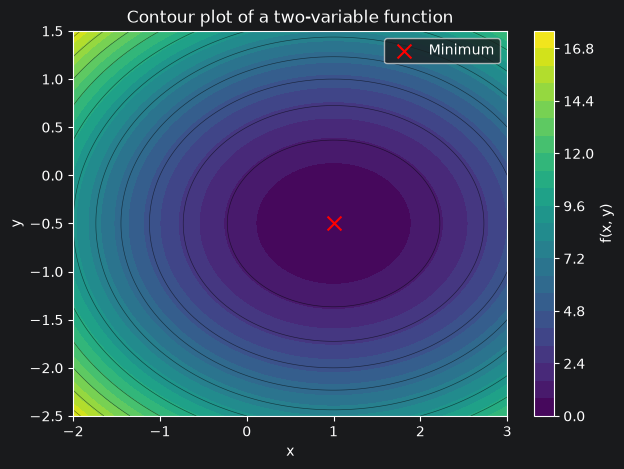

In [19]:
def surface_function(x, y):
    """A smooth two-variable function with one global minimum."""
    return (x - 1.0)**2 + 2.0 * (y + 0.5)**2

x_grid = np.linspace(-2, 3, 150)
y_grid = np.linspace(-2.5, 1.5, 150)
XX, YY = np.meshgrid(x_grid, y_grid)
ZZ = surface_function(XX, YY)

fig, ax = plt.subplots(figsize=(7, 5))
contours = ax.contourf(XX, YY, ZZ, levels=25)
ax.contour(XX, YY, ZZ, levels=12, colors="black", linewidths=0.45, alpha=0.55)
ax.scatter([1.0], [-0.5], marker="x", s=100, color="red", label="Minimum")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Contour plot of a two-variable function")
ax.legend()
fig.colorbar(contours, ax=ax, label="f(x, y)")
plt.show()

## 6.2 The Gradient

The **gradient** collects all first-order partial derivatives into a vector:

$$
\nabla f(x,y)=
\begin{bmatrix}
\frac{\partial f}{\partial x}\\
\frac{\partial f}{\partial y}
\end{bmatrix}
$$

For a differentiable function, the gradient points in the direction of steepest local increase. The negative gradient points in the direction of steepest local decrease. Gradient descent uses this property to update model parameters.

For the example $f(x,y)=(x-1)^2+2(y+0.5)^2$:

$$
\nabla f(x,y)=
\begin{bmatrix}
2(x-1)\\
4(y+0.5)
\end{bmatrix}
$$

In [20]:
def surface_gradient(x, y):
    """Analytical gradient of surface_function."""
    df_dx = 2.0 * (x - 1.0)
    df_dy = 4.0 * (y + 0.5)
    return np.array([df_dx, df_dy])

point = np.array([-1.0, 1.0])
gradient = surface_gradient(point[0], point[1])
print("Point:", point)
print("Gradient:", gradient)
print("Negative gradient:", -gradient)

Point: [-1.  1.]
Gradient: [-4.  6.]
Negative gradient: [ 4. -6.]


## 6.3 Visualizing Gradient Directions

The arrows below show the negative gradient at selected points. Each arrow points locally downhill toward the minimum. Arrow lengths are scaled for visualization; gradient descent itself uses the numerical gradient multiplied by a learning rate.

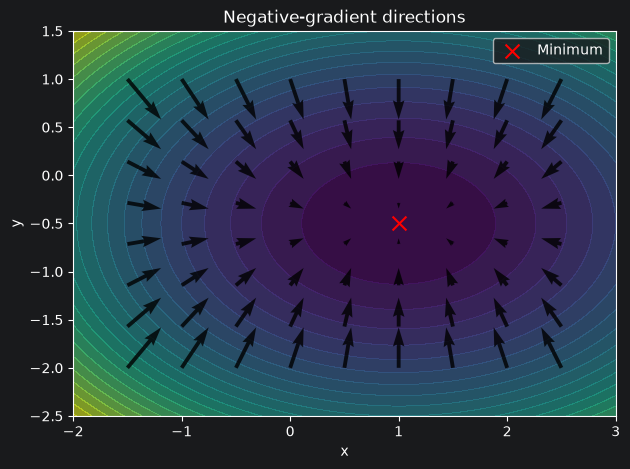

In [21]:
sample_x = np.linspace(-1.5, 2.5, 9)
sample_y = np.linspace(-2.0, 1.0, 8)
GX, GY = np.meshgrid(sample_x, sample_y)
U = -2.0 * (GX - 1.0)
V = -4.0 * (GY + 0.5)

fig, ax = plt.subplots(figsize=(7, 5))
ax.contourf(XX, YY, ZZ, levels=24, alpha=0.65)
ax.quiver(GX, GY, U, V, color="black", alpha=0.8)
ax.scatter([1.0], [-0.5], marker="x", s=100, color="red", label="Minimum")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Negative-gradient directions")
ax.legend()
plt.show()

---
# 7. The Chain Rule and Computational Graphs

## 7.1 The Chain Rule for One Variable

When one function is composed with another, the derivative is calculated using the chain rule. If $y=f(u)$ and $u=g(x)$, then:

$$
\frac{dy}{dx}=\frac{dy}{du}\frac{du}{dx}
$$

This rule is central to backpropagation. A neural network is a composition of many operations, and the gradient with respect to an early parameter is found by multiplying local derivatives along the computational path.

## 7.2 A Step-by-Step Example

Consider:

$$
u = 3x+2, \qquad y=u^2
$$

At $x=2$, we have $u=8$ and $y=64$. The derivatives are:

$$
\frac{du}{dx}=3, \qquad \frac{dy}{du}=2u=16
$$

Therefore:

$$
\frac{dy}{dx}=16\times 3=48
$$

In [22]:
x = 2.0
u = 3.0 * x + 2.0
y = u**2

du_dx = 3.0
dy_du = 2.0 * u
dy_dx = dy_du * du_dx

print("u:", u)
print("y:", y)
print("dy/du:", dy_du)
print("du/dx:", du_dx)
print("dy/dx by chain rule:", dy_dx)

# Verify with a central finite difference.
composed_function = lambda value: (3.0 * value + 2.0)**2
print("Numerical derivative:", central_difference(composed_function, x))

u: 8.0
y: 64.0
dy/du: 16.0
du/dx: 3.0
dy/dx by chain rule: 48.0
Numerical derivative: 48.00000000102499


## 7.3 Computational Graphs

A computational graph represents a calculation as a sequence of elementary operations. For the expression $y=(3x+2)^2$, the graph is:

```text
x  ---> multiply by 3 ---> add 2 ---> square ---> y
          |                  |          |
        local              local      local
      derivative 3       derivative 1  derivative 2u
```

In the forward pass, values move from inputs to outputs. In the backward pass, derivatives are propagated from the output toward earlier variables using the chain rule. This forward-then-backward structure is the conceptual basis of automatic differentiation and neural-network backpropagation.

## 7.4 A Neural-Network View of the Chain Rule

For a single neuron:

$$
z=wx+b, \qquad a=\phi(z), \qquad L=\ell(a,y)
$$

The derivative of the loss with respect to the weight is:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial a}
\frac{\partial a}{\partial z}
\frac{\partial z}{\partial w}
$$

Since $\partial z/\partial w=x$ and $\partial a/\partial z=\phi'(z)$:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial a}\phi'(z)x
$$

This equation illustrates why backpropagation needs both the derivative of the loss and the derivatives of the operations inside the network.

---
# 8. Loss Functions and the Optimization Objective

## 8.1 What Is a Loss Function?

A **loss function** measures the discrepancy between model predictions and target values. During supervised learning, training aims to find parameter values that produce a low loss on the training data while still generalizing to unseen examples.

For regression, a common choice is the mean squared error (MSE):

$$
L=\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

where $y_i$ is the target and $\hat{y}_i$ is the prediction. Squaring makes all contributions non-negative and gives larger errors greater influence.

In [23]:
y_true = np.array([1.0, 2.0, 3.0, 4.0])
y_pred = np.array([0.8, 2.4, 2.5, 4.2])

mse = np.mean((y_pred - y_true) ** 2)
mae = np.mean(np.abs(y_pred - y_true))

print("Mean squared error:", mse)
print("Mean absolute error:", mae)

Mean squared error: 0.1225
Mean absolute error: 0.325


## 8.2 A Simple One-Parameter Model

Consider the model $\hat{y}=wx$ and a dataset containing pairs $(x_i,y_i)$. Its MSE loss is:

$$
L(w)=\frac{1}{n}\sum_{i=1}^{n}(wx_i-y_i)^2
$$

The parameter $w$ is the quantity we want to optimize. Differentiating with respect to $w$ gives:

$$
\frac{dL}{dw}=\frac{2}{n}\sum_{i=1}^{n}(wx_i-y_i)x_i
$$

This small example connects the loss function to the gradient used by the optimizer.

In [24]:
x_data = np.array([1.0, 2.0, 3.0, 4.0])
y_data = np.array([2.1, 3.9, 6.2, 7.8])
w = 1.5

predictions = w * x_data
loss = np.mean((predictions - y_data) ** 2)
gradient_w = (2.0 / len(x_data)) * np.sum((predictions - y_data) * x_data)

print("Current weight:", w)
print("Predictions:", predictions)
print("MSE loss:", loss)
print("Analytical dL/dw:", gradient_w)

Current weight: 1.5
Predictions: [1.5 3.  4.5 6. ]
MSE loss: 1.825
Analytical dL/dw: -7.35


---
# 9. Gradient Descent and the Learning Rate

## 9.1 Gradient-Descent Update

Gradient descent updates parameters in the direction opposite to the gradient:

$$
\theta_{t+1}=\theta_t-\eta\nabla_{\theta}L(\theta_t)
$$

where:

- $\theta_t$ represents the parameters at iteration $t$.
- $L$ is the objective or loss function.
- $\nabla_{\theta}L$ is the gradient with respect to the parameters.
- $\eta$ is the learning rate, a positive step-size parameter.

The gradient determines a local downhill direction. The learning rate controls how far the update moves in that direction.

## 9.2 A One-Dimensional Optimization Example

We will minimize the convex function:

$$
L(w)=(w-3)^2+1
$$

Its derivative is:

$$
\frac{dL}{dw}=2(w-3)
$$

The minimum occurs at $w=3$, where the loss equals 1. We start from $w_0=-4$ and observe how gradient descent approaches the minimum.

Final parameter: 2.9998422246179652
Final loss: 1.0000000248930712
Analytical minimum: w = 3, loss = 1


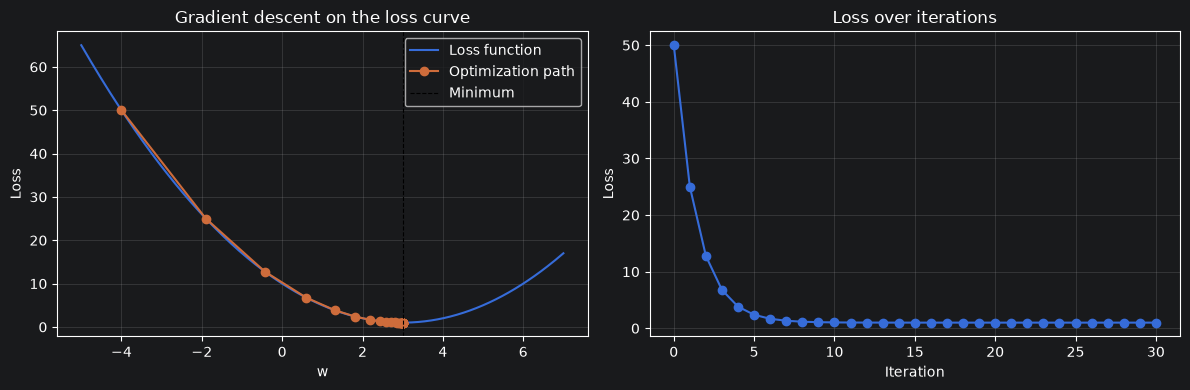

In [25]:
def objective(w):
    return (w - 3.0)**2 + 1.0

def objective_gradient(w):
    return 2.0 * (w - 3.0)

learning_rate = 0.15
w = -4.0
history = [w]
loss_history = [objective(w)]

for _ in range(30):
    w = w - learning_rate * objective_gradient(w)
    history.append(w)
    loss_history.append(objective(w))

print("Final parameter:", w)
print("Final loss:", objective(w))
print("Analytical minimum: w = 3, loss = 1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
w_values = np.linspace(-5, 7, 300)
axes[0].plot(w_values, objective(w_values), label="Loss function")
axes[0].plot(history, [objective(value) for value in history], "o-", label="Optimization path")
axes[0].axvline(3.0, color="black", linestyle="--", linewidth=0.8, label="Minimum")
axes[0].set_xlabel("w")
axes[0].set_ylabel("Loss")
axes[0].set_title("Gradient descent on the loss curve")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(loss_history, marker="o")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Loss")
axes[1].set_title("Loss over iterations")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9.3 The Effect of the Learning Rate

A learning rate that is too small may make progress very slowly. A suitable value can approach the minimum efficiently. A value that is too large can overshoot the minimum or diverge.

The appropriate learning rate depends on the shape and scale of the objective, the parameterization, and the optimizer. There is no single value that is best for every model and dataset.

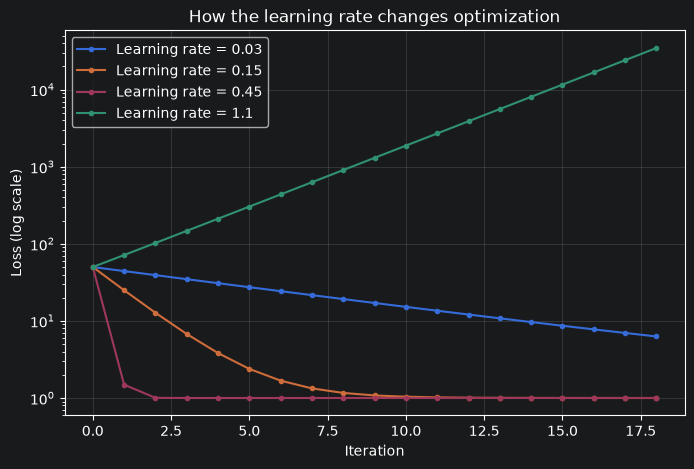

In [26]:
learning_rates = [0.03, 0.15, 0.45, 1.1]
initial_w = -4.0
iterations = 18

fig, ax = plt.subplots(figsize=(8, 5))
for rate in learning_rates:
    current_w = initial_w
    losses = []
    for _ in range(iterations + 1):
        losses.append(objective(current_w))
        current_w = current_w - rate * objective_gradient(current_w)
    ax.plot(losses, marker="o", markersize=3, label=f"Learning rate = {rate}")

ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Loss (log scale)")
ax.set_title("How the learning rate changes optimization")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 9.4 Batch, Stochastic, and Mini-Batch Gradients

When a dataset contains many samples, the gradient can be computed using:

- **Batch gradient descent:** the full training dataset is used for each update.
- **Stochastic gradient descent:** one sample is used for each update.
- **Mini-batch gradient descent:** a small subset of samples is used for each update.

Mini-batch training is widely used in deep learning because it balances computational efficiency with frequent parameter updates. The data-pipeline and training details will be covered in Notebook 03 and Notebook 07.

---
# 10. Gradient Checking and a Neural Network from Scratch

This section brings the mathematical ideas together. We will first compare analytical and numerical gradients, then implement a small multilayer perceptron using NumPy only. The network will use one hidden layer with a `tanh` activation and a linear output for a synthetic regression task.

The dataset is synthetic and exists only for learning. It should not be interpreted as biological or medical data.

## 10.1 Analytical Gradient Versus Numerical Gradient

Analytical gradients are derived using calculus and the chain rule. Numerical gradients approximate derivatives by slightly perturbing a parameter and measuring the change in loss.

For a scalar parameter $\theta_j$, the central-difference estimate is:

$$
\frac{\partial L}{\partial\theta_j}
\approx
\frac{L(\theta_j+h)-L(\theta_j-h)}{2h}
$$

Gradient checking compares these two results. A close match provides evidence that a manually implemented gradient is correct for the tested parameter and input.

## 10.2 Define a Small Regression Dataset

We will approximate a smooth nonlinear function over a one-dimensional input domain. The model will learn from 80 input points. A hidden layer with `tanh` units provides a flexible nonlinear representation, and a linear output layer produces the regression prediction.

Input shape: (80, 1)
Target shape: (80, 1)


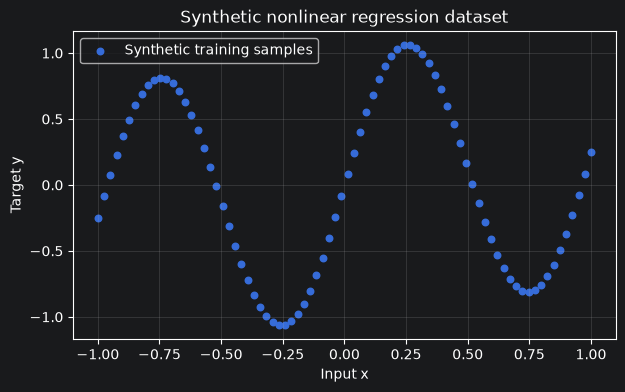

In [27]:
# Reproducible synthetic regression data.
rng = np.random.default_rng(7)
X_train = np.linspace(-1.0, 1.0, 80).reshape(-1, 1)
y_train = (np.sin(2.0 * np.pi * X_train) + 0.25 * X_train)

print("Input shape:", X_train.shape)
print("Target shape:", y_train.shape)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_train[:, 0], y_train[:, 0], s=22, label="Synthetic training samples")
ax.set_xlabel("Input x")
ax.set_ylabel("Target y")
ax.set_title("Synthetic nonlinear regression dataset")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 10.3 Network Architecture and Forward Pass

Let $m$ be the number of samples, $d$ the number of input features, and $h$ the number of hidden units. The network calculations are:

$$
\mathbf{Z}_1=\mathbf{X}\mathbf{W}_1+\mathbf{b}_1
$$

$$
\mathbf{A}_1=\tanh(\mathbf{Z}_1)
$$

$$
\hat{\mathbf{Y}}=\mathbf{A}_1\mathbf{W}_2+\mathbf{b}_2
$$

For this example, the shapes are:

| Quantity | Shape |
|---|---|
| $\mathbf{X}$ | $(m,d)$ |
| $\mathbf{W}_1$ | $(d,h)$ |
| $\mathbf{b}_1$ | $(1,h)$ |
| $\mathbf{A}_1$ | $(m,h)$ |
| $\mathbf{W}_2$ | $(h,1)$ |
| $\mathbf{b}_2$ | $(1,1)$ |
| $\hat{\mathbf{Y}}$ | $(m,1)$ |

In [28]:
input_dim = X_train.shape[1]
hidden_units = 24
output_dim = 1

# Small random initial parameters. The scaling keeps initial activations moderate.
W1 = rng.normal(0.0, 0.5, size=(input_dim, hidden_units))
b1 = np.zeros((1, hidden_units))
W2 = rng.normal(0.0, 0.2, size=(hidden_units, output_dim))
b2 = np.zeros((1, output_dim))

print("W1:", W1.shape, "b1:", b1.shape)
print("W2:", W2.shape, "b2:", b2.shape)

W1: (1, 24) b1: (1, 24)
W2: (24, 1) b2: (1, 1)


### Forward Pass Function

The forward-pass function returns the prediction, intermediate activations, and loss. Keeping intermediate values is useful because backpropagation needs them to calculate derivatives.

In [29]:
def forward_pass(X, y, W1, b1, W2, b2):
    """Run a one-hidden-layer MLP forward pass and return cached values."""
    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)
    y_pred = A1 @ W2 + b2
    loss = np.mean((y_pred - y) ** 2)
    cache = {"Z1": Z1, "A1": A1, "y_pred": y_pred}
    return loss, cache

initial_loss, initial_cache = forward_pass(X_train, y_train, W1, b1, W2, b2)
print("Initial MSE:", initial_loss)
print("Prediction shape:", initial_cache["y_pred"].shape)

Initial MSE: 0.43390484329445567
Prediction shape: (80, 1)


## 10.4 Deriving Backpropagation for the Network

The loss is mean squared error:

$$
L=\frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)^2
$$

The derivative with respect to the output is:

$$
\frac{\partial L}{\partial\hat{\mathbf{Y}}}
=\frac{2}{m}(\hat{\mathbf{Y}}-\mathbf{Y})
$$

For the output layer:

$$
\frac{\partial L}{\partial\mathbf{W}_2}
=\mathbf{A}_1^T\frac{\partial L}{\partial\hat{\mathbf{Y}}},
\qquad
\frac{\partial L}{\partial\mathbf{b}_2}
=\sum_{i=1}^{m}\frac{\partial L}{\partial\hat{\mathbf{Y}}_i}
$$

The gradient is propagated to the hidden activation:

$$
\frac{\partial L}{\partial\mathbf{A}_1}
=\frac{\partial L}{\partial\hat{\mathbf{Y}}}\mathbf{W}_2^T
$$

Because the derivative of $\tanh(z)$ is $1-\tanh^2(z)$:

$$
\frac{\partial L}{\partial\mathbf{Z}_1}
=\frac{\partial L}{\partial\mathbf{A}_1}\odot(1-\mathbf{A}_1^2)
$$

Finally, for the first layer:

$$
\frac{\partial L}{\partial\mathbf{W}_1}
=\mathbf{X}^T\frac{\partial L}{\partial\mathbf{Z}_1},
\qquad
\frac{\partial L}{\partial\mathbf{b}_1}
=\sum_{i=1}^{m}\frac{\partial L}{\partial\mathbf{Z}_{1,i}}
$$

The matrix shapes follow directly from these products. The sums over the batch dimension produce one bias gradient per hidden unit or output unit.

### Implement Backpropagation

The code below implements the derivatives from the previous derivation. It uses `keepdims=True` when summing bias gradients so that the resulting arrays retain a two-dimensional shape and remain consistent with the bias parameters.

In [30]:
def compute_gradients(X, y, W1, b1, W2, b2):
    """Compute MSE loss and analytical gradients for the MLP."""
    sample_count = X.shape[0]
    loss, cache = forward_pass(X, y, W1, b1, W2, b2)

    A1 = cache["A1"]
    y_pred = cache["y_pred"]

    dY_pred = (2.0 / sample_count) * (y_pred - y)
    dW2 = A1.T @ dY_pred
    db2 = np.sum(dY_pred, axis=0, keepdims=True)

    dA1 = dY_pred @ W2.T
    dZ1 = dA1 * (1.0 - A1**2)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
    return loss, gradients

loss, gradients = compute_gradients(X_train, y_train, W1, b1, W2, b2)
for parameter_name, gradient in gradients.items():
    print(f"dL/d{parameter_name} shape: {gradient.shape}")

dL/dW1 shape: (1, 24)
dL/db1 shape: (1, 24)
dL/dW2 shape: (24, 1)
dL/db2 shape: (1, 1)


## 10.5 Gradient Checking for One Weight

We will check one element of $\mathbf{W}_1$. The parameter is perturbed by $+h$ and $-h$, and the resulting losses are used to estimate the derivative numerically. This is a useful debugging technique when implementing backpropagation manually.

In [31]:
parameter_index = (0, 0)
step = 1e-5

W1_plus = W1.copy()
W1_minus = W1.copy()
W1_plus[parameter_index] += step
W1_minus[parameter_index] -= step

loss_plus, _ = forward_pass(X_train, y_train, W1_plus, b1, W2, b2)
loss_minus, _ = forward_pass(X_train, y_train, W1_minus, b1, W2, b2)
numerical_gradient = (loss_plus - loss_minus) / (2.0 * step)
analytical_gradient = gradients["W1"][parameter_index]
absolute_difference = abs(numerical_gradient - analytical_gradient)

print("Numerical gradient:", numerical_gradient)
print("Analytical gradient:", analytical_gradient)
print("Absolute difference:", absolute_difference)
assert np.isclose(numerical_gradient, analytical_gradient, rtol=1e-3, atol=1e-6)

Numerical gradient: 0.003696251230089764
Analytical gradient: 0.0036962512263731553
Absolute difference: 3.716608618087314e-12


## 10.6 Train the Network with Gradient Descent

We now update every parameter using the same gradient-descent rule. The data are small, so full-batch gradient descent is sufficient for this educational example.

In [32]:
# Reinitialize the model so that the training run is self-contained.
rng = np.random.default_rng(7)
W1 = rng.normal(0.0, 0.5, size=(input_dim, hidden_units))
b1 = np.zeros((1, hidden_units))
W2 = rng.normal(0.0, 0.2, size=(hidden_units, output_dim))
b2 = np.zeros((1, output_dim))

learning_rate = 0.08
training_steps = 10000
loss_history = []

for step_index in range(training_steps):
    loss, grads = compute_gradients(X_train, y_train, W1, b1, W2, b2)
    W1 -= learning_rate * grads["W1"]
    b1 -= learning_rate * grads["b1"]
    W2 -= learning_rate * grads["W2"]
    b2 -= learning_rate * grads["b2"]
    loss_history.append(loss)

final_loss, final_cache = forward_pass(X_train, y_train, W1, b1, W2, b2)
print(f"Initial loss: {loss_history[0]:.6f}")
print(f"Final loss:   {final_loss:.6f}")
print(f"Training steps: {training_steps}")

Initial loss: 0.433905
Final loss:   0.051606
Training steps: 10000


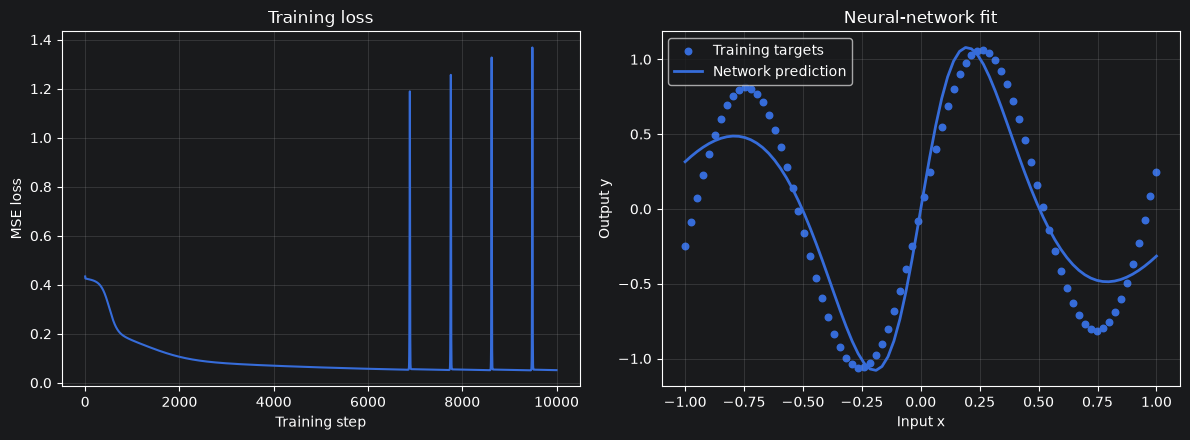

In [33]:
# Visualize the optimization history and fitted function.
y_pred = final_cache["y_pred"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(loss_history)
axes[0].set_xlabel("Training step")
axes[0].set_ylabel("MSE loss")
axes[0].set_title("Training loss")
axes[0].grid(alpha=0.25)

axes[1].scatter(X_train[:, 0], y_train[:, 0], s=22, label="Training targets")
axes[1].plot(X_train[:, 0], y_pred[:, 0], linewidth=2, label="Network prediction")
axes[1].set_xlabel("Input x")
axes[1].set_ylabel("Output y")
axes[1].set_title("Neural-network fit")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Interpreting the Result

A successful run should show a decreasing training loss and a prediction curve that follows the general shape of the synthetic target function. The exact final loss can vary slightly with numerical-library versions and implementation details, but the loss should be substantially lower than its initial value.

This experiment demonstrates the main mathematical ideas behind training: matrix operations perform the forward pass, the chain rule produces gradients, and gradient descent updates the model parameters. Later notebooks will use TensorFlow and Keras to automate differentiation and provide production-ready training tools.

---
# 11. Common Mathematical and Implementation Mistakes

| Mistake | Why it is a problem | Better practice |
|---|---|---|
| Confusing `*` with `@` | Element-wise multiplication and matrix multiplication are different operations. | Write down the intended operation and check shapes. |
| Ignoring array shapes | A valid operation can still represent the wrong axis convention. | Label axes as samples, features, or units. |
| Treating an affine map as linear | A nonzero bias shifts the output. | Distinguish $\mathbf{x}\mathbf{W}$ from $\mathbf{x}\mathbf{W}+\mathbf{b}$. |
| Forgetting the chain rule | Gradients through composed operations will be incomplete. | Break the computation into intermediate variables. |
| Using an excessively large learning rate | Updates may overshoot or diverge. | Inspect the loss curve and test a smaller learning rate. |
| Summing bias gradients over the wrong axis | The gradient shape may not match the bias parameter. | Sum over samples and keep the intended dimensions. |
| Assuming a zero gradient always means a minimum | It can also be a maximum or saddle point. | Inspect the local function geometry or curvature. |
| Trusting a manual gradient without testing | A small algebra or indexing error can corrupt training. | Use finite-difference gradient checks on small examples. |

## 11.1 A Quick Shape Debugging Checklist

Before executing a matrix expression, ask:

1. What does each axis represent?
2. What is the shape of each operand?
3. Do the inner dimensions match for matrix multiplication?
4. Does the output shape match the intended number of samples and units?
5. Are bias vectors broadcast along the intended axis?

---
# 12. Summary and Further Practice

## 12.1 Key Takeaways

- Scalars, vectors, matrices, and higher-dimensional tensors are distinguished by their number of dimensions and shapes.
- Dot products combine vectors into scalars; matrix multiplication combines compatible arrays according to their inner dimensions.
- A dense layer applies an affine transformation, followed by an activation function.
- Nonlinear activations are essential for multilayer networks to represent nonlinear mappings.
- Derivatives measure rates of change; partial derivatives describe changes with respect to individual variables.
- The gradient collects partial derivatives and points in the direction of steepest local increase.
- The chain rule allows gradients to pass backward through a sequence of operations.
- Gradient descent updates parameters in the negative-gradient direction, with the learning rate controlling the step size.
- Numerical gradient checking is a practical way to test a manually derived backpropagation implementation.

## 12.2 Glossary

| Term | Meaning |
|---|---|
| Scalar | A single numerical value. |
| Vector | An ordered one-dimensional array of values. |
| Matrix | A two-dimensional array of values. |
| Tensor | A general numerical array with zero or more dimensions. |
| Shape | The size of an array along each axis. |
| Dot product | A sum of pairwise products of corresponding vector elements. |
| Norm | A measure of the size or length of a vector or matrix. |
| Transpose | An operation that exchanges matrix rows and columns. |
| Linear transformation | A mapping that preserves addition and scalar multiplication. |
| Affine transformation | A linear transformation followed by a translation. |
| Derivative | The instantaneous rate of change of a function. |
| Partial derivative | A derivative with respect to one variable while other variables are held fixed. |
| Gradient | The vector of partial derivatives of a scalar-valued function. |
| Chain rule | A rule for differentiating composed functions. |
| Loss function | A numerical measure of prediction error. |
| Gradient descent | An iterative method that updates parameters opposite to the gradient. |
| Learning rate | A parameter controlling the size of gradient-descent updates. |
| Backpropagation | Efficient calculation of neural-network gradients using the chain rule. |

## 12.3 Exercises

Complete these exercises before moving to Notebook 03. Try to solve them without copying the code cells above.

### Exercise 1 — Shapes and Tensors

Create a NumPy array representing 12 samples with 5 features. Report its shape, number of dimensions, and number of elements. Reshape it to `(12, 5, 1)` and explain what changed and what did not change.

### Exercise 2 — Dot Product

For $\mathbf{x}=[2,-1,3]$ and $\mathbf{w}=[0.5,4,-2]$, calculate the dot product by hand and verify it with `np.dot`.

### Exercise 3 — Matrix Multiplication

Create matrices with shapes `(4, 3)` and `(3, 2)`. Calculate their product and explain why the output shape is `(4, 2)`. Then create an incompatible pair and inspect the error.

### Exercise 4 — Linear Versus Affine

Plot $y=-1.5x$ and $y=-1.5x+2$. Explain why the first is linear and the second is affine but not linear.

### Exercise 5 — Numerical Derivative

For $f(x)=x^3-4x$, derive the analytical derivative. Compare it with a central-difference estimate at $x=2$ for several step sizes.

### Exercise 6 — Gradient Descent

Minimize $L(w)=(w+2)^2$ using gradient descent. Start at $w_0=5$. Test at least three learning rates and plot the loss over iterations.

### Exercise 7 — Chain Rule

For $u=2x-1$ and $y=u^3$, calculate $dy/dx$ at $x=2$ using the chain rule. Confirm the result numerically.

### Exercise 8 — Extend the NumPy Neural Network

Change the number of hidden units in the final network. Compare the training loss and fitted curve. Explain why increasing the number of hidden units does not guarantee better generalization.

### Optional Challenge — Full Gradient Check

Extend gradient checking to every element of `W1`, `b1`, `W2`, and `b2`. Report the maximum absolute difference between analytical and numerical gradients. Use a small subset of parameters if the numerical calculation becomes slow.

## 12.4 Suggested Reading

1. Goodfellow, Bengio, and Courville, **Deep Learning**, Chapter 2: Linear Algebra; Chapter 4: Numerical Computation; Chapter 6: Deep Feedforward Networks. [Online book contents](https://www.deeplearningbook.org/contents/TOC.html)
2. NumPy documentation: [Array basics](https://numpy.org/doc/stable/user/basics.html).
3. NumPy documentation: [Matrix multiplication](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html).
4. NumPy documentation: [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html).

---

## Next Notebook

**Notebook 03 — TensorFlow, Keras, and Data Pipelines** will connect these mathematical foundations to tensors, automatic differentiation with `tf.GradientTape`, Keras model APIs, and efficient data input pipelines.